<a href="https://colab.research.google.com/github/AfraazUlHaque/Non-Linear-SVM/blob/main/BreastCancer_NLSVMipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset samples: 569
Features: ['Mean radius', 'Mean texture']
Malignant: 212
Benign: 357

Training iterations: 567
Number of support vectors: 135
Test accuracy: 92.11%


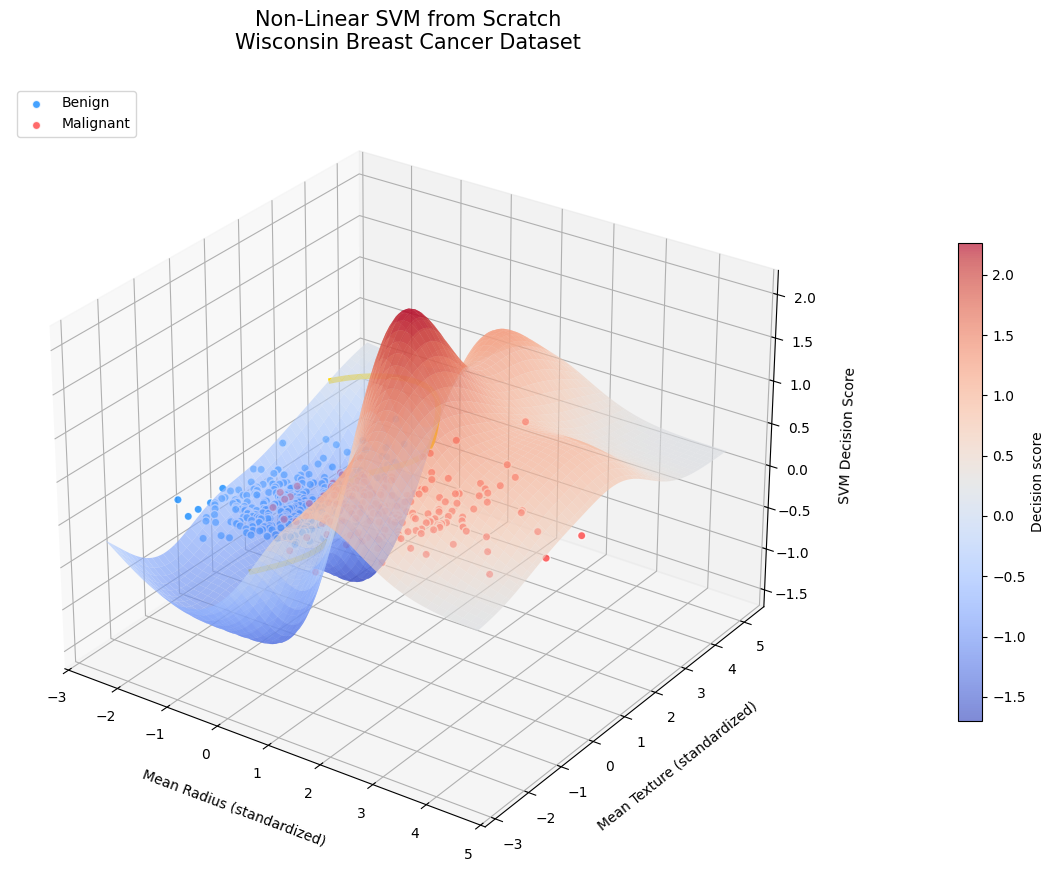

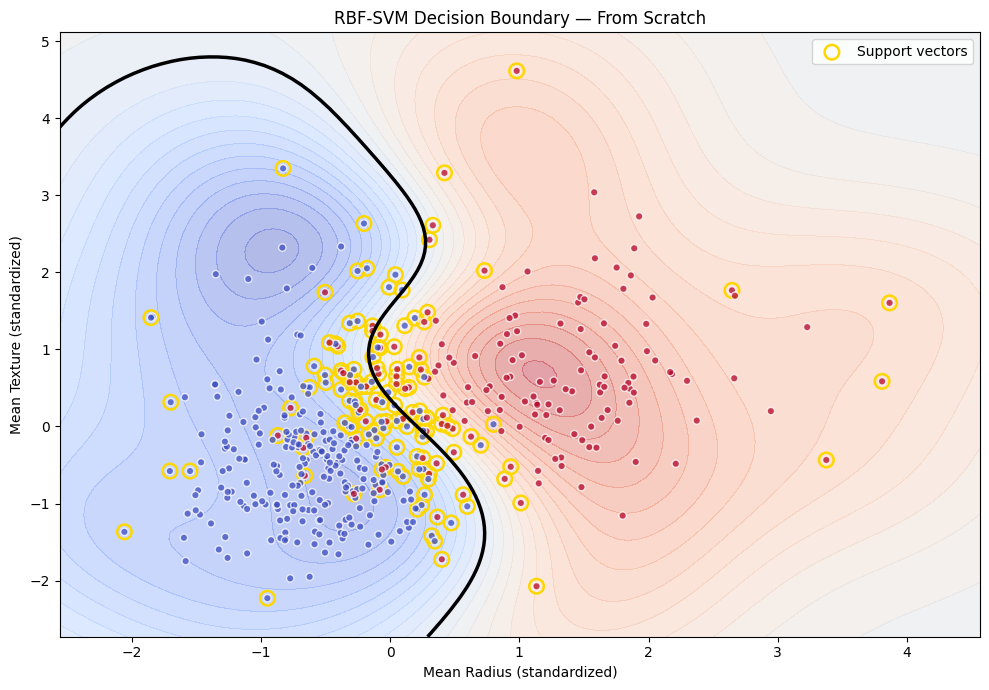

In [1]:
import csv
import urllib.request
import numpy as np
import matplotlib.pyplot as plt

from mpl_toolkits.mplot3d import Axes3D

# ------------------------------------------------------------
# 1. LOAD REAL WISCONSIN BREAST CANCER DATASET
# ------------------------------------------------------------

url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
)

with urllib.request.urlopen(url) as response:
    rows = list(csv.reader(
        response.read().decode("utf-8").splitlines()
    ))

# Columns:
# 0 = ID, 1 = Diagnosis, 2 = radius_mean, 3 = texture_mean
# B = Benign (-1), M = Malignant (+1)

X = np.array([
    [float(row[2]), float(row[3])]
    for row in rows
])

y = np.array([
    1.0 if row[1] == "M" else -1.0
    for row in rows
])

print("Dataset samples:", len(X))
print("Features:", ["Mean radius", "Mean texture"])
print("Malignant:", np.sum(y == 1))
print("Benign:", np.sum(y == -1))

# ------------------------------------------------------------
# 2. TRAIN-TEST SPLIT (WITHOUT SKLEARN)
# ------------------------------------------------------------

rng = np.random.default_rng(42)
indices = rng.permutation(len(X))

split = int(0.8 * len(X))
train_idx = indices[:split]
test_idx = indices[split:]

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

# Standardization using training data only
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

# ------------------------------------------------------------
# 3. RBF KERNEL FROM SCRATCH
# ------------------------------------------------------------

def rbf_kernel(A, B, gamma=0.5):
    A_sq = np.sum(A**2, axis=1)[:, None]
    B_sq = np.sum(B**2, axis=1)[None, :]

    distances = np.maximum(
        A_sq + B_sq - 2 * A @ B.T, 0
    )

    return np.exp(-gamma * distances)


# ------------------------------------------------------------
# 4. SVM TRAINING USING SIMPLIFIED SMO
# ------------------------------------------------------------

def train_svm(X, y, C=1.0, gamma=0.5,
              tol=1e-3, max_passes=8, max_iter=30000):

    n = len(X)
    K = rbf_kernel(X, X, gamma)

    alpha = np.zeros(n)
    b = 0.0

    passes = 0
    iterations = 0

    while passes < max_passes and iterations < max_iter:
        changed = 0

        for i in range(n):
            f_i = np.sum(alpha * y * K[:, i]) + b
            E_i = f_i - y[i]

            if not (
                (y[i] * E_i < -tol and alpha[i] < C)
                or
                (y[i] * E_i > tol and alpha[i] > 0)
            ):
                continue

            # Select a second point
            j = rng.integers(n - 1)
            if j >= i:
                j += 1

            f_j = np.sum(alpha * y * K[:, j]) + b
            E_j = f_j - y[j]

            old_ai = alpha[i]
            old_aj = alpha[j]

            if y[i] != y[j]:
                L = max(0, old_aj - old_ai)
                H = min(C, C + old_aj - old_ai)
            else:
                L = max(0, old_ai + old_aj - C)
                H = min(C, old_ai + old_aj)

            if L == H:
                continue

            eta = 2 * K[i, j] - K[i, i] - K[j, j]

            if eta >= 0:
                continue

            alpha[j] -= (
                y[j] * (E_i - E_j) / eta
            )

            alpha[j] = np.clip(alpha[j], L, H)

            if abs(alpha[j] - old_aj) < 1e-5:
                alpha[j] = old_aj
                continue

            alpha[i] += (
                y[i] * y[j] * (old_aj - alpha[j])
            )

            b1 = (
                b - E_i
                - y[i] * (alpha[i] - old_ai) * K[i, i]
                - y[j] * (alpha[j] - old_aj) * K[i, j]
            )

            b2 = (
                b - E_j
                - y[i] * (alpha[i] - old_ai) * K[i, j]
                - y[j] * (alpha[j] - old_aj) * K[j, j]
            )

            if 0 < alpha[i] < C:
                b = b1
            elif 0 < alpha[j] < C:
                b = b2
            else:
                b = (b1 + b2) / 2

            changed += 1

        passes = passes + 1 if changed == 0 else 0
        iterations += 1

    support_mask = alpha > 1e-5

    return (
        X[support_mask],
        y[support_mask],
        alpha[support_mask],
        b,
        iterations
    )


# ------------------------------------------------------------
# 5. DECISION FUNCTION FROM SCRATCH
# ------------------------------------------------------------

def decision_function(X_new, support_X, support_y,
                      support_alpha, b, gamma=0.5):

    K = rbf_kernel(X_new, support_X, gamma)

    return K @ (support_alpha * support_y) + b


# Train
C = 1.0
gamma = 0.5

support_X, support_y, support_alpha, b, iterations = train_svm(
    X_train, y_train, C=C, gamma=gamma
)

print("\nTraining iterations:", iterations)
print("Number of support vectors:", len(support_X))

# Test accuracy
test_scores = decision_function(
    X_test, support_X, support_y,
    support_alpha, b, gamma
)

test_pred = np.where(test_scores >= 0, 1, -1)

accuracy = np.mean(test_pred == y_test) * 100
print(f"Test accuracy: {accuracy:.2f}%")

# ------------------------------------------------------------
# 6. BUILD A GRID FOR THE 3D DECISION SURFACE
# ------------------------------------------------------------

# Convert original feature limits into standardized coordinates
X_all_scaled = (X - mean) / std

x_min, x_max = (
    X_all_scaled[:, 0].min() - 0.5,
    X_all_scaled[:, 0].max() + 0.5
)

y_min, y_max = (
    X_all_scaled[:, 1].min() - 0.5,
    X_all_scaled[:, 1].max() + 0.5
)

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 100),
    np.linspace(y_min, y_max, 100)
)

grid = np.c_[xx.ravel(), yy.ravel()]

Z = decision_function(
    grid, support_X, support_y,
    support_alpha, b, gamma
).reshape(xx.shape)

# ------------------------------------------------------------
# 7. BEAUTIFUL 3D DECISION BOUNDARY
# ------------------------------------------------------------

fig = plt.figure(figsize=(13, 9))
ax = fig.add_subplot(111, projection="3d")

# Nonlinear decision score surface
surface = ax.plot_surface(
    xx, yy, Z,
    cmap="coolwarm",
    alpha=0.65,
    linewidth=0,
    antialiased=True
)

# Project the zero-level decision boundary onto z = 0
ax.contour(
    xx, yy, Z,
    levels=[0],
    zdir="z",
    offset=0,
    colors=["#FFD700"],
    linewidths=4
)

# Actual data points projected onto the zero plane
ax.scatter(
    X_train[y_train == -1, 0],
    X_train[y_train == -1, 1],
    np.zeros(np.sum(y_train == -1)),
    color="#168BFF",
    edgecolors="white",
    s=35,
    alpha=0.8,
    label="Benign"
)

ax.scatter(
    X_train[y_train == 1, 0],
    X_train[y_train == 1, 1],
    np.zeros(np.sum(y_train == 1)),
    color="#FF4545",
    edgecolors="white",
    s=35,
    alpha=0.8,
    label="Malignant"
)

ax.set_xlabel("Mean Radius (standardized)", labelpad=12)
ax.set_ylabel("Mean Texture (standardized)", labelpad=12)
ax.set_zlabel("SVM Decision Score", labelpad=12)

ax.set_title(
    "Non-Linear SVM from Scratch\n"
    "Wisconsin Breast Cancer Dataset",
    pad=25,
    fontsize=15
)

ax.set_zlim(Z.min(), Z.max())
ax.view_init(elev=28, azim=-55)
ax.legend(loc="upper left")

fig.colorbar(
    surface, ax=ax, shrink=0.6, pad=0.12,
    label="Decision score"
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. OPTIONAL: 2D DECISION BOUNDARY
# ------------------------------------------------------------

plt.figure(figsize=(10, 7))

plt.contourf(
    xx, yy, Z,
    levels=30,
    cmap="coolwarm",
    alpha=0.4
)

plt.contour(
    xx, yy, Z,
    levels=[0],
    colors="black",
    linewidths=2.5
)

# Show support vectors
plt.scatter(
    support_X[:, 0],
    support_X[:, 1],
    s=110,
    facecolors="none",
    edgecolors="gold",
    linewidths=1.8,
    label="Support vectors"
)

plt.scatter(
    X_train[:, 0], X_train[:, 1],
    c=y_train,
    cmap="coolwarm",
    edgecolors="white",
    s=28,
    alpha=0.75
)

plt.xlabel("Mean Radius (standardized)")
plt.ylabel("Mean Texture (standardized)")
plt.title("RBF-SVM Decision Boundary — From Scratch")
plt.legend()
plt.tight_layout()
plt.show()